In [112]:
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Cleaning Data 

## Weather and AQ Data

In [113]:
weather_df = pd.read_csv("../raw/weather.csv")
weather_df

,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,2024-01-01 00:00:00,22.8,19,28.0,0.2,NaN,NaN,10.7,NaN,1016.8,NaN
1,2024-01-02 00:00:00,23.4,21,27.0,0.1,NaN,NaN,11.7,NaN,1016.0,NaN
2,2024-01-03 00:00:00,19.5,17,22.0,9.7,NaN,NaN,13.0,NaN,1019.9,NaN
3,2024-01-04 00:00:00,19.1,17,21.0,0.0,NaN,NaN,8.8,NaN,1019.0,NaN
4,2024-01-05 00:00:00,20.2,18,23.0,0.0,NaN,NaN,6.5,NaN,1017.6,NaN
...,...,...,...,...,...,...,...,...,...,...,...
361,2024-12-27 00:00:00,18.4,17,20.0,0.0,NaN,NaN,14.4,NaN,1024.2,NaN
362,2024-12-28 00:00:00,18.8,15,23.0,0.0,NaN,NaN,12.3,NaN,1025.9,NaN
363,2024-12-29 00:00:00,18.0,14,22.0,0.0,NaN,NaN,10.7,NaN,1021.5,NaN
364,2024-12-30 00:00:00,17.6,13,21.0,0.0,NaN,NaN,7.3,NaN,1020.6,NaN


In [114]:
aq_df = pd.read_csv("../raw/air_quality.csv")
aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_dioxide (ppm),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),methane (μg/m³)
0,2024-01-01T00:00,59.8,40.0,26.0,36.0,36.8,NaN,702.0,0.0,0.46,0.0,0.0,NaN
1,2024-01-01T01:00,60.1,40.7,23.0,33.4,36.3,NaN,716.0,0.0,0.48,0.0,0.0,NaN
2,2024-01-01T02:00,61.7,42.0,20.0,31.6,35.7,NaN,732.0,0.0,0.52,0.0,0.0,NaN
3,2024-01-01T03:00,65.2,44.5,17.0,30.4,35.2,NaN,754.0,0.0,0.52,0.0,0.0,NaN
4,2024-01-01T04:00,68.9,47.1,15.0,30.5,35.1,NaN,778.0,0.0,0.51,0.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31T19:00,101.7,101.5,51.0,47.8,41.9,476.0,1998.0,0.0,0.71,0.0,0.0,1747.0
8780,2024-12-31T20:00,105.2,104.8,49.0,49.3,41.0,477.0,1915.0,0.0,0.69,0.0,0.0,1766.0
8781,2024-12-31T21:00,108.5,108.3,46.0,51.2,39.6,477.0,1618.0,0.0,0.66,0.0,0.0,1765.0
8782,2024-12-31T22:00,112.9,112.7,43.0,51.4,38.1,477.0,1365.0,0.0,0.64,0.0,0.0,1765.0


In [115]:
weather_df["date"] = pd.to_datetime(weather_df["date"], errors="coerce")
aq_df["time"] = pd.to_datetime(aq_df["time"], errors="coerce")

## Creating QA and deleted flag column

In [116]:
qa_logs = []
def qa_log(dataset, rule, count, total):
    qa_logs.append({
        "dataset": dataset,
        "rule": rule,
        "count": int(count),
        "total": int(total),
        "percent": round(100 * count / total, 4) if total else np.nan
    })

In [117]:
weather_df["is_deleted_wt"] = False
aq_df["is_deleted_aq"] = False

## Handle missing data

### Weather

In [118]:
for c in weather_df.columns:
    mask = weather_df[c].isna()
    qa_log("weather", f"Weather Missing {c}", mask.sum(), len(weather_df))

In [119]:
weather_df.isna().sum()

date               0
tavg               0
tmin               0
tmax               0
prcp              12
snow             366
wdir             366
wspd               0
wpgt             366
pres               0
tsun             366
is_deleted_wt      0
dtype: int64

"snow", "wdir", "wpgt", "tsun" missing 100% -> drop columns 

"prcp" missing 12/366 -> analyze data first

In [120]:
drop_cols = ["snow", "wdir", "wpgt", "tsun"]
weather_df = weather_df.drop(columns=drop_cols)

<Axes: xlabel='date'>

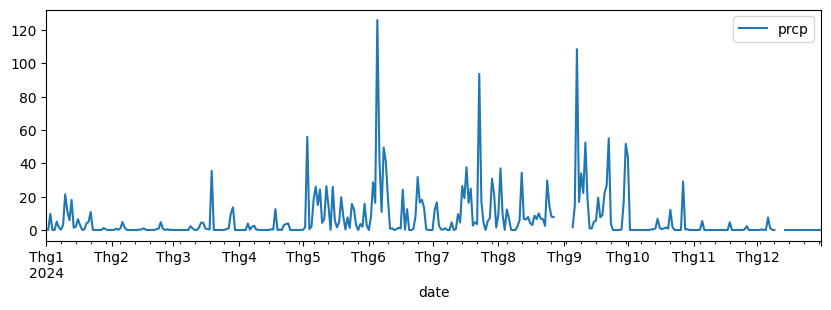

In [121]:
weather_df.plot(kind="line", x="date", y="prcp", figsize=(10,3))

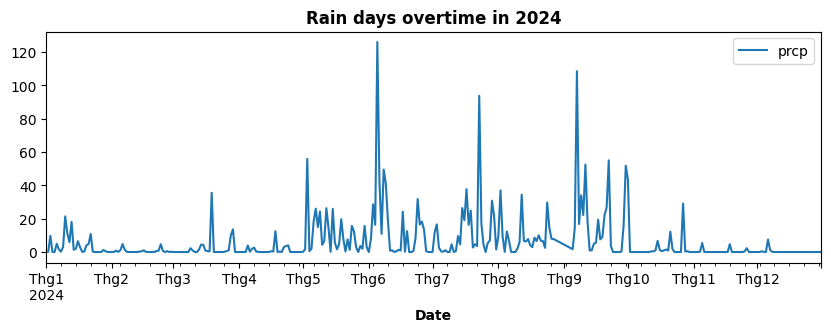

<Figure size 640x480 with 0 Axes>

In [195]:
weather_df["prcp"] = weather_df["prcp"].interpolate(method="linear")
ax = weather_df.plot(kind="line", y="prcp", figsize=(10,3))
ax.set_xlabel("Date", fontweight="bold")
ax.set_title("Rain days overtime in 2024", fontweight="bold")

plt.show()
plt.savefig("../figures/rain_days_over_time.png", dpi=300, bbox_inches='tight')

### Air Quality

In [123]:
for c in aq_df.columns:
    mask = aq_df[c].isna()
    qa_log("air_quality", f"AQ Missing {c}", mask.sum(), len(aq_df))

In [124]:
print(aq_df.shape[0])
aq_df.isna().sum()

8784


time                           0
pm10 (μg/m³)                   0
pm2_5 (μg/m³)                  0
ozone (μg/m³)                  0
sulphur_dioxide (μg/m³)        0
nitrogen_dioxide (μg/m³)       0
carbon_dioxide (ppm)        7183
carbon_monoxide (μg/m³)        0
uv_index ()                    0
aerosol_optical_depth ()       0
dust (μg/m³)                   0
uv_index_clear_sky ()          0
methane (μg/m³)             7183
is_deleted_aq                  0
dtype: int64

"carbon_dioxide" and "methane" are missing 7183/8784 (81.77%) -> drop columns

In [125]:
drop_cols = ["carbon_dioxide (ppm)", "methane (μg/m³)"]
aq_df = aq_df.drop(columns=drop_cols)
aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted_aq
0,2024-01-01 00:00:00,59.8,40.0,26.0,36.0,36.8,702.0,0.0,0.46,0.0,0.0,False
1,2024-01-01 01:00:00,60.1,40.7,23.0,33.4,36.3,716.0,0.0,0.48,0.0,0.0,False
2,2024-01-01 02:00:00,61.7,42.0,20.0,31.6,35.7,732.0,0.0,0.52,0.0,0.0,False
3,2024-01-01 03:00:00,65.2,44.5,17.0,30.4,35.2,754.0,0.0,0.52,0.0,0.0,False
4,2024-01-01 04:00:00,68.9,47.1,15.0,30.5,35.1,778.0,0.0,0.51,0.0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,101.7,101.5,51.0,47.8,41.9,1998.0,0.0,0.71,0.0,0.0,False
8780,2024-12-31 20:00:00,105.2,104.8,49.0,49.3,41.0,1915.0,0.0,0.69,0.0,0.0,False
8781,2024-12-31 21:00:00,108.5,108.3,46.0,51.2,39.6,1618.0,0.0,0.66,0.0,0.0,False
8782,2024-12-31 22:00:00,112.9,112.7,43.0,51.4,38.1,1365.0,0.0,0.64,0.0,0.0,False


## Check negative values

In [126]:
weather_df

,date,tavg,tmin,tmax,prcp,wspd,pres,is_deleted_wt
0,2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,False
1,2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,False
2,2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,False
3,2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,False
4,2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,False
...,...,...,...,...,...,...,...,...
361,2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,False
362,2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,False
363,2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,False
364,2024-12-30,17.6,13,21.0,0.0,7.3,1020.6,False


In [127]:
check_weather_neg_cols = ["prcp", "wspd", "pres"]
for col in check_weather_neg_cols:
    mask = weather_df[col].apply(lambda x: False if pd.isna(x) else x < 0)
    weather_df["is_deleted_wt"] = weather_df["is_deleted_wt"] | mask
    qa_log("weather", f"Weather negative {col}", mask.sum(), len(weather_df))

In [128]:
aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted_aq
0,2024-01-01 00:00:00,59.8,40.0,26.0,36.0,36.8,702.0,0.0,0.46,0.0,0.0,False
1,2024-01-01 01:00:00,60.1,40.7,23.0,33.4,36.3,716.0,0.0,0.48,0.0,0.0,False
2,2024-01-01 02:00:00,61.7,42.0,20.0,31.6,35.7,732.0,0.0,0.52,0.0,0.0,False
3,2024-01-01 03:00:00,65.2,44.5,17.0,30.4,35.2,754.0,0.0,0.52,0.0,0.0,False
4,2024-01-01 04:00:00,68.9,47.1,15.0,30.5,35.1,778.0,0.0,0.51,0.0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,101.7,101.5,51.0,47.8,41.9,1998.0,0.0,0.71,0.0,0.0,False
8780,2024-12-31 20:00:00,105.2,104.8,49.0,49.3,41.0,1915.0,0.0,0.69,0.0,0.0,False
8781,2024-12-31 21:00:00,108.5,108.3,46.0,51.2,39.6,1618.0,0.0,0.66,0.0,0.0,False
8782,2024-12-31 22:00:00,112.9,112.7,43.0,51.4,38.1,1365.0,0.0,0.64,0.0,0.0,False


In [129]:
check_aq_neg_cols = aq_df.columns.drop("time").tolist()
for col in check_aq_neg_cols:
    mask = aq_df[col].apply(lambda x: False if pd.isna(x) else x < 0)
    aq_df["is_deleted_aq"] = aq_df["is_deleted_aq"] | mask
    qa_log("air_quality", f"AQ negative {col}", mask.sum(), len(aq_df))

## Check if PM2.5 > PM10

In [130]:
mask = (aq_df["pm2_5 (μg/m³)"] > aq_df["pm10 (μg/m³)"])
aq_df["is_deleted_aq"] = aq_df["is_deleted_aq"] | mask
qa_log("air_quality", "PM2.5 > PM10", mask.sum(), len(aq_df))

## Check if there are duplicated timestamp

In [131]:
dup_weather_mask = weather_df.duplicated("date", keep=False)
weather_df["is_deleted_wt"] = weather_df["is_deleted_wt"] | dup_weather_mask
qa_log("weather", "Weather duplicate timestamps", dup_weather_mask.sum(), len(weather_df))

In [132]:
dup_aq_mask = aq_df.duplicated("time", keep=False)
aq_df["is_deleted_aq"] = aq_df["is_deleted_aq"] | dup_aq_mask
qa_log("air_quality", "AQ duplicate timestamps", dup_aq_mask.sum(), len(aq_df))

## Check if there are missing timestamps

In [133]:
start = weather_df["date"].min()
end = weather_df["date"].max()
ts = pd.date_range(start=start, end=end, freq="d")
weather_missing_ts = len(ts) - weather_df["date"].nunique()
qa_log("weather", "Weather missing timestamps", weather_missing_ts, len(ts))

weather_missing_ts

0

In [134]:
start = aq_df["time"].min()
end = aq_df["time"].max()
ts = pd.date_range(start=start, end=end, freq="h")
aq_missing_ts = len(ts) - aq_df["time"].nunique()
qa_log("air_quality", "AQ missing timestamps", aq_missing_ts, len(ts))

aq_missing_ts

0

In [135]:
weather_df

,date,tavg,tmin,tmax,prcp,wspd,pres,is_deleted_wt
0,2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,False
1,2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,False
2,2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,False
3,2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,False
4,2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,False
...,...,...,...,...,...,...,...,...
361,2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,False
362,2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,False
363,2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,False
364,2024-12-30,17.6,13,21.0,0.0,7.3,1020.6,False


In [136]:
aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted_aq
0,2024-01-01 00:00:00,59.8,40.0,26.0,36.0,36.8,702.0,0.0,0.46,0.0,0.0,False
1,2024-01-01 01:00:00,60.1,40.7,23.0,33.4,36.3,716.0,0.0,0.48,0.0,0.0,False
2,2024-01-01 02:00:00,61.7,42.0,20.0,31.6,35.7,732.0,0.0,0.52,0.0,0.0,False
3,2024-01-01 03:00:00,65.2,44.5,17.0,30.4,35.2,754.0,0.0,0.52,0.0,0.0,False
4,2024-01-01 04:00:00,68.9,47.1,15.0,30.5,35.1,778.0,0.0,0.51,0.0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,101.7,101.5,51.0,47.8,41.9,1998.0,0.0,0.71,0.0,0.0,False
8780,2024-12-31 20:00:00,105.2,104.8,49.0,49.3,41.0,1915.0,0.0,0.69,0.0,0.0,False
8781,2024-12-31 21:00:00,108.5,108.3,46.0,51.2,39.6,1618.0,0.0,0.66,0.0,0.0,False
8782,2024-12-31 22:00:00,112.9,112.7,43.0,51.4,38.1,1365.0,0.0,0.64,0.0,0.0,False


## Resample hourly -> daily in AQ

In [137]:
aq_df = aq_df.set_index("time").sort_index()

In [138]:
aq_num_cols = aq_df.select_dtypes(include=[np.number]).columns.tolist()
agg_map = {c: "mean" for c in aq_num_cols}
agg_map["is_deleted_aq"] = "max"

masked = aq_df.copy()
masked.loc[masked['is_deleted_aq'], aq_num_cols] = np.nan

aq_daily_df = masked.resample('D').agg(agg_map)
aq_daily_df = aq_daily_df.round(2)

In [139]:
aq_daily_df

,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted_aq
time,,,,,,,,,,,
2024-01-01,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
2024-01-02,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2024-01-03,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
2024-01-04,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
2024-01-05,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
2024-12-28,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
2024-12-29,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False


## Merge 2 datas

In [140]:
weather_df = weather_df.set_index("date").sort_index()

In [141]:
clean_df = pd.merge(weather_df, aq_daily_df, left_index=True, right_index=True)
clean_df["is_deleted"] = clean_df["is_deleted_aq"] | clean_df["is_deleted_wt"]
clean_df = clean_df.drop(columns=["is_deleted_aq", "is_deleted_wt"])
clean_df

,tavg,tmin,tmax,prcp,wspd,pres,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted
date,,,,,,,,,,,,,,,,,
2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False


In [142]:
processed_dir = Path("../processed")
reports_dir = Path("../reports")

clean_df.to_csv(processed_dir / "final_data.csv", index=True)

In [143]:
qa_df = pd.DataFrame(qa_logs)
qa_df["decision"] = ""
qa_df.loc[4, "decision"] = "Fill NA by using interpolation"
qa_df.loc[[5, 6, 8, 10, 18, 24], "decision"] = "Drop column"
qa_df

,dataset,rule,count,total,percent,decision
0,weather,Weather Missing date,0,366,0.0000,
1,weather,Weather Missing tavg,0,366,0.0000,
2,weather,Weather Missing tmin,0,366,0.0000,
3,weather,Weather Missing tmax,0,366,0.0000,
4,weather,Weather Missing prcp,12,366,3.2787,Fill NA by using interpolation
5,weather,Weather Missing snow,366,366,100.0000,Drop column
6,weather,Weather Missing wdir,366,366,100.0000,Drop column
7,weather,Weather Missing wspd,0,366,0.0000,
8,weather,Weather Missing wpgt,366,366,100.0000,Drop column
9,weather,Weather Missing pres,0,366,0.0000,


In [144]:
qa_df.to_csv(reports_dir / "qa_summary.csv", index=False)

In [145]:
clean_df

,tavg,tmin,tmax,prcp,wspd,pres,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted
date,,,,,,,,,,,,,,,,,
2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False


In [146]:
qa_summary = pd.read_csv("../reports/qa_summary.csv")
qa_summary

,dataset,rule,count,total,percent,decision
0,weather,Weather Missing date,0,366,0.0000,NaN
1,weather,Weather Missing tavg,0,366,0.0000,NaN
2,weather,Weather Missing tmin,0,366,0.0000,NaN
3,weather,Weather Missing tmax,0,366,0.0000,NaN
4,weather,Weather Missing prcp,12,366,3.2787,Fill NA by using interpolation
5,weather,Weather Missing snow,366,366,100.0000,Drop column
6,weather,Weather Missing wdir,366,366,100.0000,Drop column
7,weather,Weather Missing wspd,0,366,0.0000,NaN
8,weather,Weather Missing wpgt,366,366,100.0000,Drop column
9,weather,Weather Missing pres,0,366,0.0000,NaN


# Summary & Statistics

In [147]:
daily_stats_series = pd.Series({
    "temp_mean": clean_df["tavg"].mean(),
    "temp_p50": clean_df["tavg"].quantile(0.5),
    "temp_p95": clean_df["tavg"].quantile(0.95),

    "prcp_sum": clean_df["prcp"].sum(),
    "prcp_days_than_1mm": (clean_df["prcp"] >= 1).sum(),

    "wspd_mean": clean_df["wspd"].mean(),
    "pres_mean": clean_df["pres"].mean(),

    "pm25_p95": clean_df["pm2_5 (μg/m³)"].quantile(0.95),
    "pm10_p95": clean_df["pm10 (μg/m³)"].quantile(0.95),
    "pm25_exceed_days": (clean_df["pm2_5 (μg/m³)"] > 15).sum(),
    "pm10_exceed_days": (clean_df["pm10 (μg/m³)"] > 45).sum(),

    "uv_max_daily_mean": clean_df["uv_index ()"].mean()
    
}).round(2)

In [148]:
daily_stats = daily_stats_series.reset_index()
daily_stats.columns = ["criteria", "value"]

In [149]:
daily_stats["unit of measurement"] = ["oC", "oC", "oC", "mm", "day", "km/h", "hPa", "μg/m³", "μg/m³", "day", "day", "index"]
daily_stats["formula"] = ["mean", "quantile", "quantile", "sum", "count", "mean", "mean", "quantile", "quantile", "count", "count", "mean"]
daily_stats

,criteria,value,unit of measurement,formula
0,temp_mean,25.16,oC,mean
1,temp_p50,26.70,oC,quantile
2,temp_p95,31.40,oC,quantile
3,prcp_sum,2306.20,mm,sum
4,prcp_days_than_1mm,169.00,day,count
5,wspd_mean,10.35,km/h,mean
6,pres_mean,1010.67,hPa,mean
7,pm25_p95,83.02,μg/m³,quantile
8,pm10_p95,112.82,μg/m³,quantile
9,pm25_exceed_days,360.00,day,count


In [150]:
daily_stats.to_csv(processed_dir / "daily_weather_aqi_21.0167_105.8_2024.csv", index=False)

In [151]:
stats = pd.read_csv("../processed/daily_weather_aqi_21.0167_105.8_2024.csv")
stats

,criteria,value,unit of measurement,formula
0,temp_mean,25.16,oC,mean
1,temp_p50,26.70,oC,quantile
2,temp_p95,31.40,oC,quantile
3,prcp_sum,2306.20,mm,sum
4,prcp_days_than_1mm,169.00,day,count
5,wspd_mean,10.35,km/h,mean
6,pres_mean,1010.67,hPa,mean
7,pm25_p95,83.02,μg/m³,quantile
8,pm10_p95,112.82,μg/m³,quantile
9,pm25_exceed_days,360.00,day,count


# Visualization

## Daily temperature

In [152]:
tavg_df = clean_df.copy()
tavg_df = tavg_df.reset_index()
tavg_df

,date,tavg,tmin,tmax,prcp,wspd,pres,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted
0,2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
1,2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2,2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
3,2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
4,2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
362,2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
363,2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False
364,2024-12-30,17.6,13,21.0,0.0,7.3,1020.6,82.79,81.74,56.12,48.88,37.63,1261.17,0.46,0.97,0.00,0.85,False


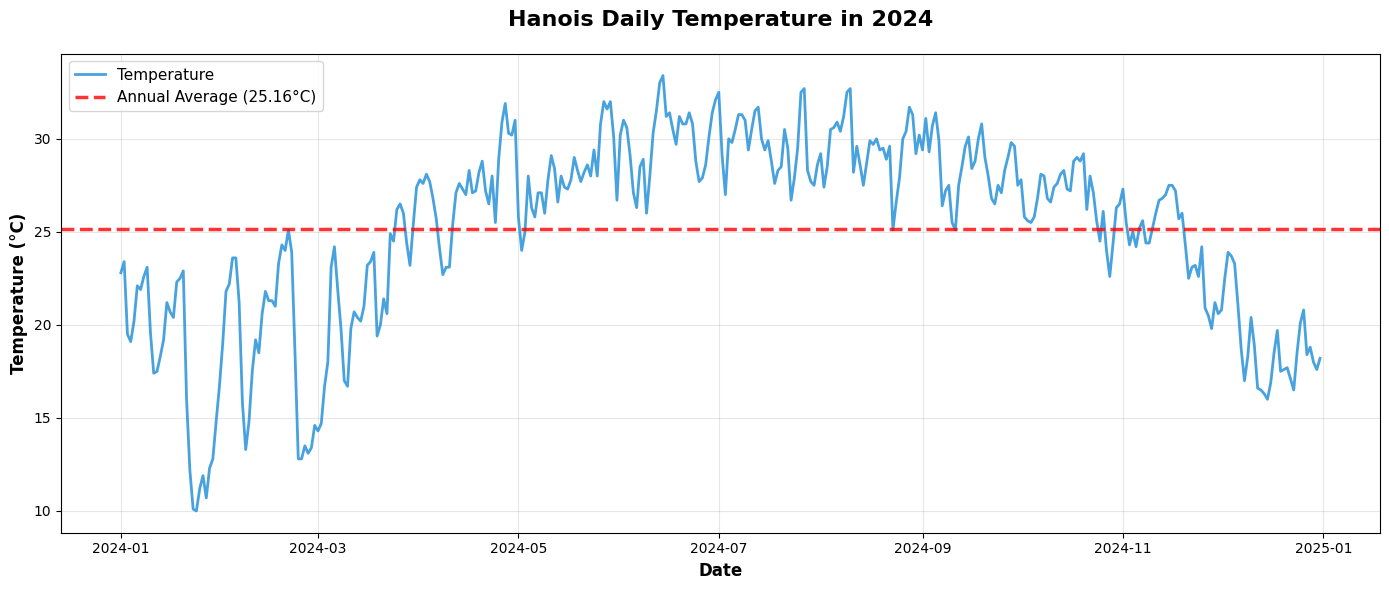

In [153]:
plt.figure(figsize=(14, 6))

plt.plot(tavg_df['date'], tavg_df['tavg'], 
         color='#3498db', linewidth=2, alpha=0.9, label='Temperature')

stats = pd.read_csv("../processed/daily_weather_aqi_21.0167_105.8_2024.csv")
temp_mean = stats[stats['criteria'] == 'temp_mean']['value'].values[0]
plt.axhline(y=temp_mean, color='red', linestyle='--', linewidth=2.5, 
            label=f'Annual Average ({temp_mean}°C)', alpha=0.8)

plt.title('Hanois Daily Temperature in 2024', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Date', fontsize=12, fontweight='bold')
plt.ylabel('Temperature (°C)', fontsize=12, fontweight='bold')
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("../figures/temp_over_time.png", dpi=300, bbox_inches='tight')
plt.show()

## PM2.5 & PM10

In [154]:
pm_df = clean_df.reset_index()
pm_df

,date,tavg,tmin,tmax,prcp,wspd,pres,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted
0,2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
1,2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2,2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
3,2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
4,2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
362,2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
363,2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False
364,2024-12-30,17.6,13,21.0,0.0,7.3,1020.6,82.79,81.74,56.12,48.88,37.63,1261.17,0.46,0.97,0.00,0.85,False


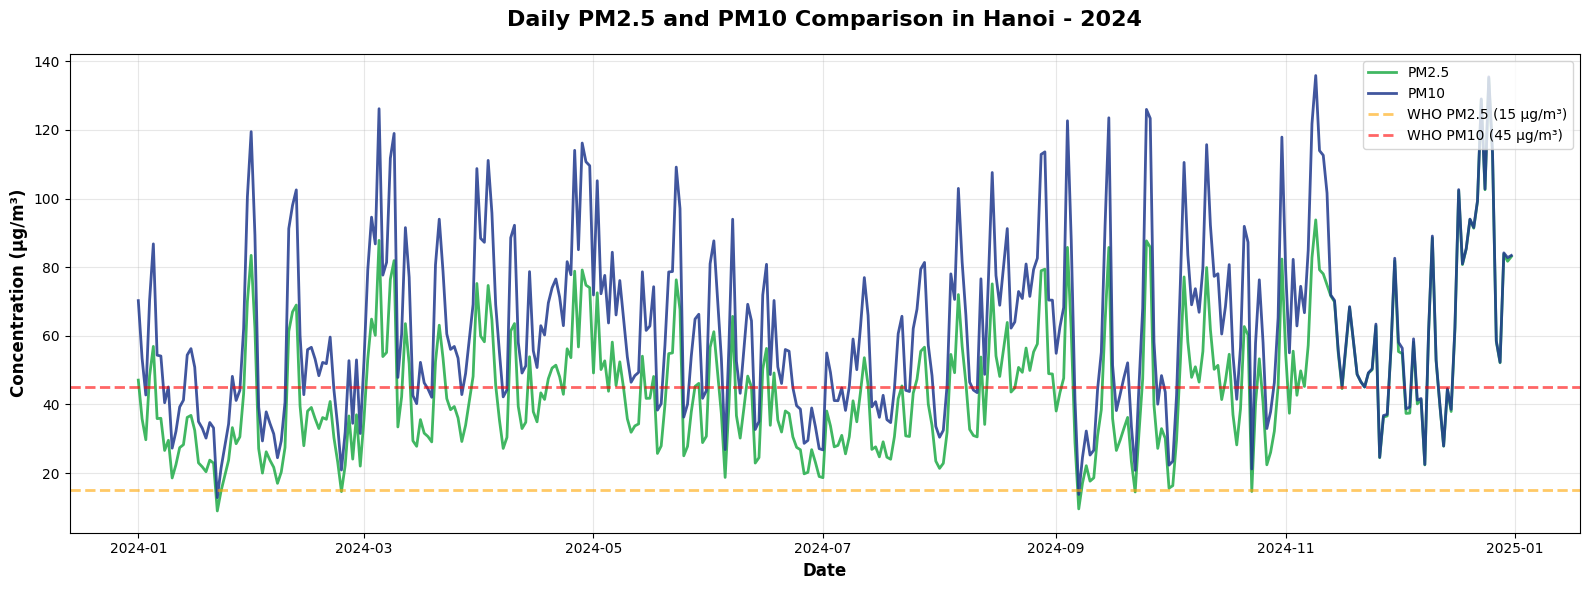

In [155]:
fig, ax = plt.subplots(figsize=(16, 6))

# PM2.5
ax.plot(pm_df['date'], pm_df['pm2_5 (μg/m³)'], 
        color="#1fab47", linewidth=2, alpha=0.85, label='PM2.5')

# PM10
ax.plot(pm_df['date'], pm_df['pm10 (μg/m³)'], 
        color="#1F388D", linewidth=2, alpha=0.85, label='PM10')

# Ngưỡng WHO
ax.axhline(y=15, color='orange', linestyle='--', linewidth=2, 
           label='WHO PM2.5 (15 μg/m³)', alpha=0.6)
ax.axhline(y=45, color='red', linestyle='--', linewidth=2, 
           label='WHO PM10 (45 μg/m³)', alpha=0.6)

ax.set_title('Daily PM2.5 and PM10 Comparison in Hanoi - 2024', 
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('Concentration (μg/m³)', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../figures/pm10_vs_pm2.5_over_time.png", dpi=300, bbox_inches='tight')
plt.show()

## PM2.5 Exceeded days

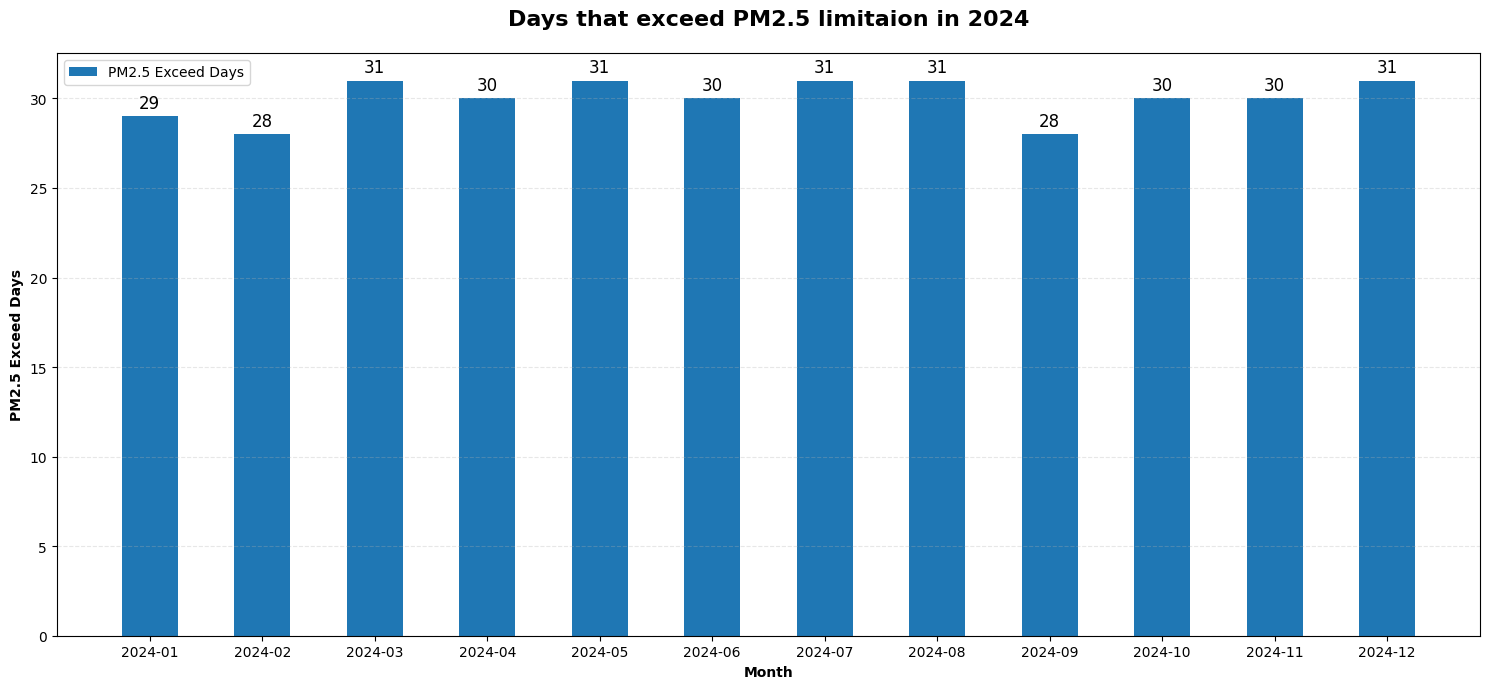

In [156]:
daily_pm25 = clean_df['pm2_5 (μg/m³)'].resample('D').mean()
pm25_exceed = (daily_pm25 > 15).resample('ME').sum()

plt.figure(figsize=(15, 7))
x_label = pm25_exceed.index.strftime('%Y-%m')

bars = plt.bar(x_label, pm25_exceed.values, label='PM2.5 Exceed Days', width=0.5)

plt.bar_label(bars, padding=3, fmt="%d", fontsize=12)

plt.title('Days that exceed PM2.5 limitaion in 2024', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Month', fontweight='bold')
plt.ylabel('PM2.5 Exceed Days', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.savefig('../figures/PM2.5_Exceed_Days.png')

plt.show()

## Heatmap hour x weekday

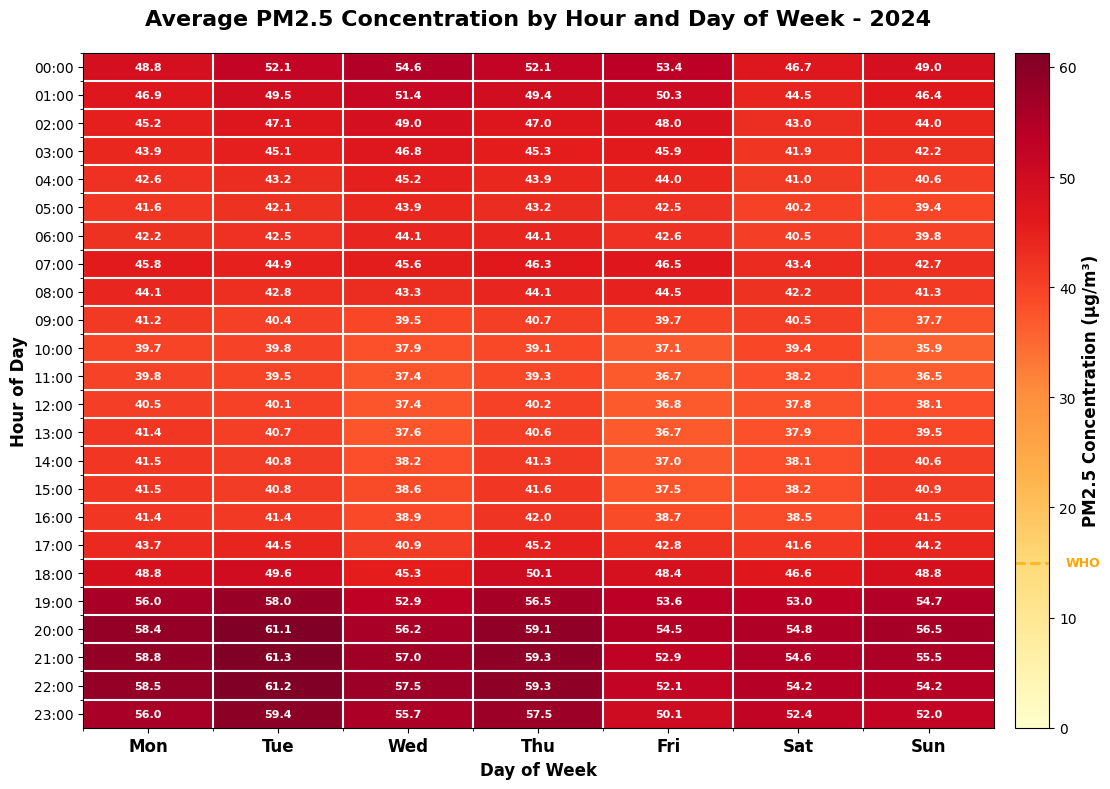

In [157]:
hourly_df = pd.read_csv("../raw/air_quality.csv")
hourly_df['time'] = pd.to_datetime(hourly_df['time'])
hourly_df['hour'] = hourly_df['time'].dt.hour
hourly_df['day_of_week'] = hourly_df['time'].dt.day_name()

heatmap_data = hourly_df.pivot_table(
    values='pm2_5 (μg/m³)', 
    index='hour', 
    columns='day_of_week', 
    aggfunc='mean'
)

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = heatmap_data.reindex(columns=day_order)

fig, ax = plt.subplots(figsize=(12, 8))

im = ax.imshow(heatmap_data.values, cmap='YlOrRd', aspect='auto', vmin=0)

ax.set_xticks(np.arange(len(day_order)))
ax.set_yticks(np.arange(24))
ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], 
                   fontsize=12, fontweight='bold')
ax.set_yticklabels([f'{h:02d}:00' for h in range(24)], fontsize=10)

for i in range(24):
    for j in range(len(day_order)):
        value = heatmap_data.values[i, j]
        color = 'white' if value > 30 else 'black'
        text = ax.text(j, i, f'{value:.1f}',
                      ha="center", va="center", 
                      color=color, fontsize=8, fontweight='bold')

cbar = plt.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('PM2.5 Concentration (μg/m³)', fontsize=12, fontweight='bold')
cbar.ax.tick_params(labelsize=10)

cbar.ax.axhline(y=15, color='orange', linestyle='--', linewidth=2, alpha=0.7)
cbar.ax.text(1.5, 15, 'WHO', va='center', fontsize=9, color='orange', fontweight='bold')

ax.set_title('Average PM2.5 Concentration by Hour and Day of Week - 2024', 
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Day of Week', fontsize=12, fontweight='bold')
ax.set_ylabel('Hour of Day', fontsize=12, fontweight='bold')

ax.set_xticks(np.arange(len(day_order)) - 0.5, minor=True)
ax.set_yticks(np.arange(24) - 0.5, minor=True)
ax.grid(which="minor", color="white", linestyle='-', linewidth=1.5)

plt.tight_layout()
plt.savefig("../figures/pm25_heatmap_hour_weekday.png", dpi=300, bbox_inches='tight')
plt.show()

hourly_avg = heatmap_data.mean(axis=1)
daily_avg = heatmap_data.mean(axis=0)
peak_hour = hourly_avg.idxmax()
peak_day = daily_avg.idxmax()

## Rain days per month

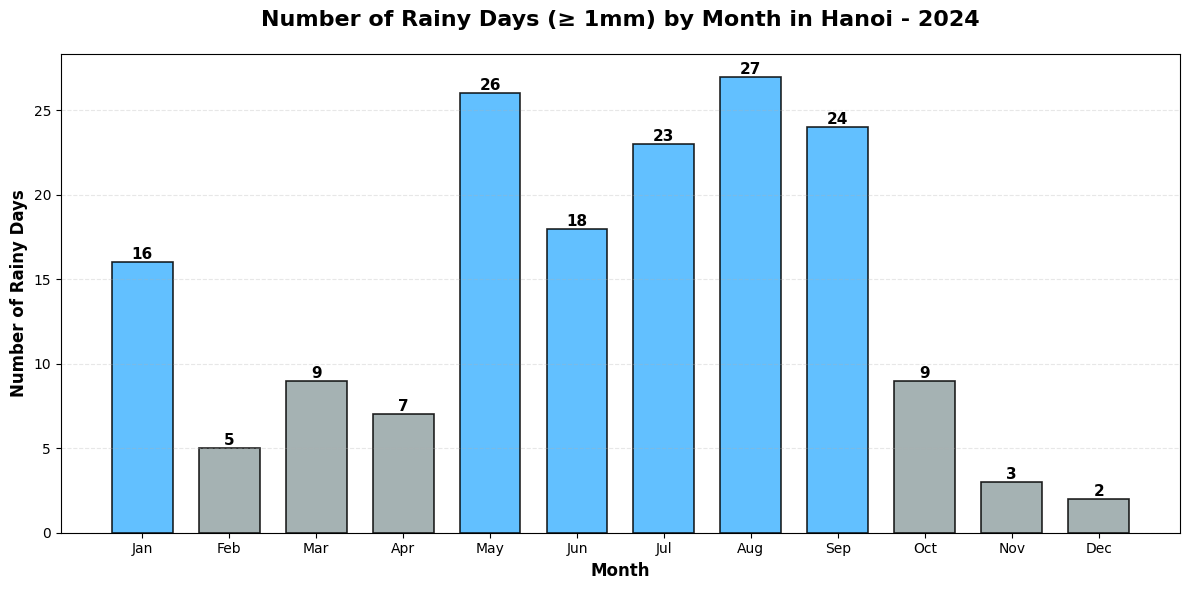

In [158]:
monthly_df = clean_df[clean_df["prcp"] >= 1].copy()
monthly_df.reset_index(inplace=True)

monthly_df["month"] = monthly_df["date"].dt.to_period("M")
rain_days = monthly_df.groupby("month")["prcp"].count().reset_index()

plt.figure(figsize=(12, 6))

counts = rain_days["prcp"]

colors = ["#46b5ff" if x > 10 else '#95a5a6' for x in counts]
bars = plt.bar(rain_days.index, counts, color=colors, 
               edgecolor='black', linewidth=1.2, alpha=0.85, width=0.7)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2., height,
             f'{int(height)}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Number of Rainy Days (≥ 1mm) by Month in Hanoi - 2024', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Month', fontsize=12, fontweight='bold')
plt.ylabel('Number of Rainy Days', fontsize=12, fontweight='bold')
plt.xticks(range(0, 12), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

plt.savefig("../figures/rain_days_by_month.png", dpi=300, bbox_inches='tight')

plt.show()

## Carbon Dioxide 

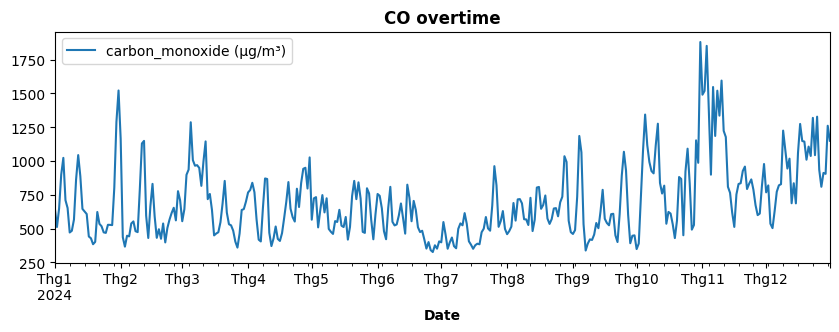

In [186]:
ax = clean_df.plot(kind="line", y="carbon_monoxide (μg/m³)", figsize=(10,3))
ax.set_title("CO overtime", fontweight="bold")
ax.set_xlabel("Date", fontweight="bold")
plt.savefig("../figures/CO_overtime.png", dpi=300, bbox_inches='tight')

## Rain & PM2.5 correlation

C:\Users\Admin\AppData\Local\Temp\ipykernel_24116\4249838520.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='filtered_rain', y='pm2_5 (μg/m³)',ax=axes, palette="Set2")


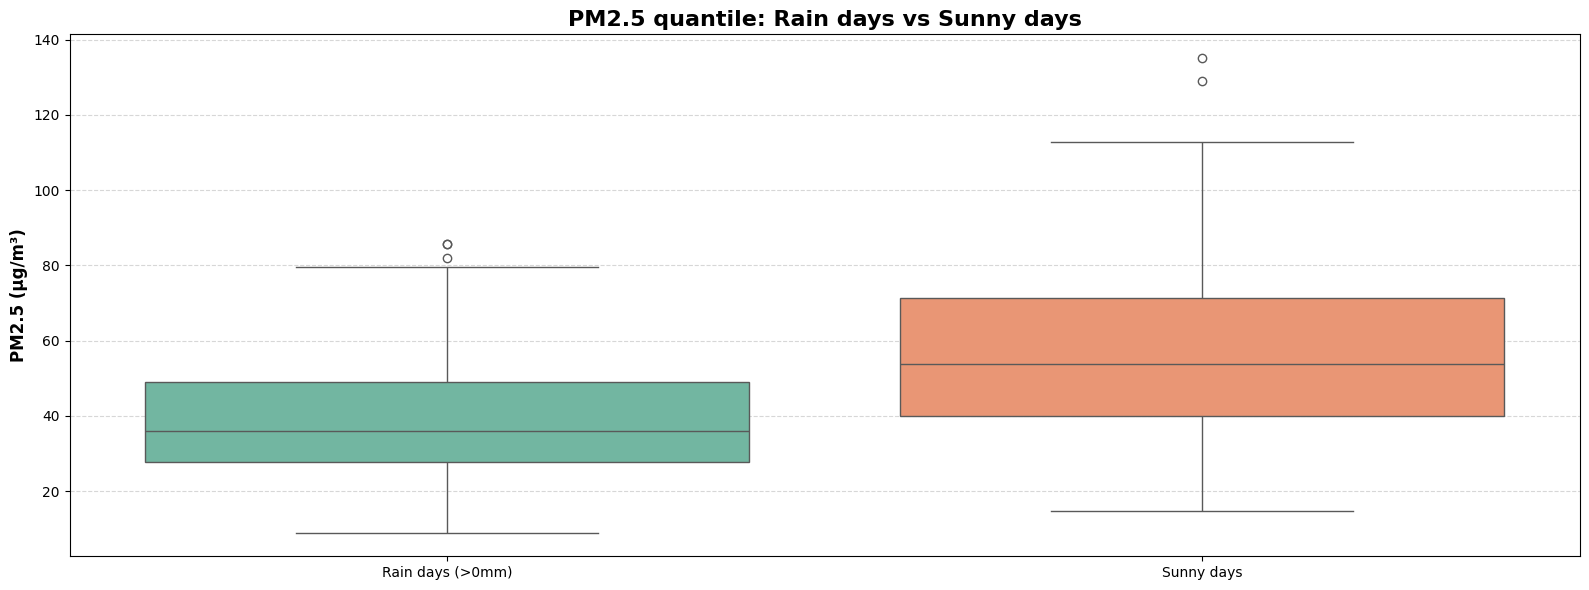

In [196]:
df = clean_df[clean_df['is_deleted'] == False].copy()

df['filtered_rain'] = df['prcp'].apply(lambda x: 'Rain days (>0mm)' if x > 0 else 'Sunny days')
fig, axes = plt.subplots(1, 1, figsize=(16, 6))
sns.boxplot(data=df, x='filtered_rain', y='pm2_5 (μg/m³)',ax=axes, palette="Set2")

axes.set_title('PM2.5 quantile: Rain days vs Sunny days', fontweight='bold',fontsize=16)
axes.set_xlabel('', fontweight="bold")
axes.set_ylabel('PM2.5 (µg/m³)', fontweight="bold", fontsize=12)
axes.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
plt.savefig("../figures/rain_days_and_pm2.5_corr.png", dpi=300, bbox_inches='tight')
plt.show()

## Wind speed & PM2.5 correlation

C:\Users\Admin\AppData\Local\Temp\ipykernel_24116\1968325575.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='filtered_wspd', y='pm2_5 (μg/m³)', ax=axes, palette="Set2")


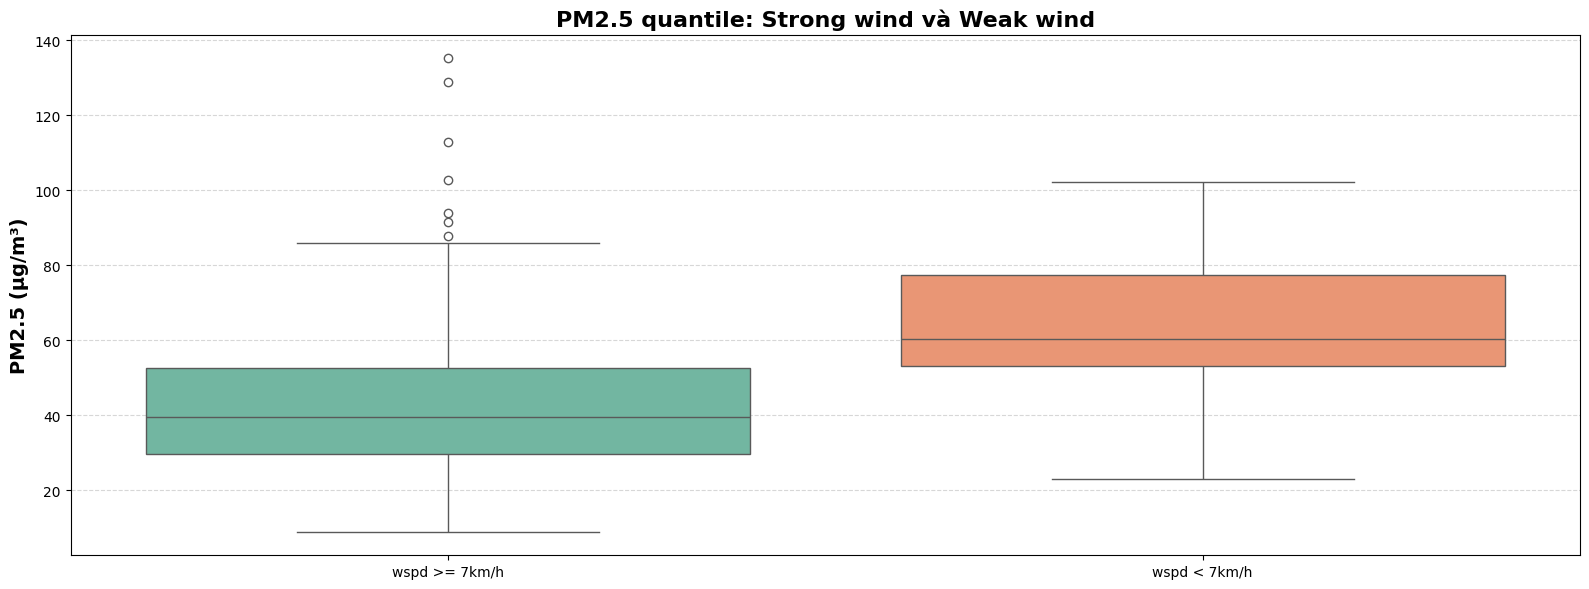

In [197]:
df = clean_df[clean_df['is_deleted'] == False].copy()

df['filtered_wspd'] = df['wspd'].apply(lambda x: 'wspd >= 7km/h' if x >= 7 else 'wspd < 7km/h')
fig, axes = plt.subplots(1, 1, figsize=(16, 6))
sns.boxplot(data=df, x='filtered_wspd', y='pm2_5 (μg/m³)', ax=axes, palette="Set2")

axes.set_title('PM2.5 quantile: Strong wind và Weak wind', fontweight='bold', fontsize=16)
axes.set_xlabel('')
axes.set_ylabel('PM2.5 (µg/m³)', fontweight="bold", fontsize=14)
axes.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
plt.savefig("../figures/wspd_and_pm2.5_corr.png", dpi=300, bbox_inches='tight')
plt.show()

## UV Index & UV clear sky

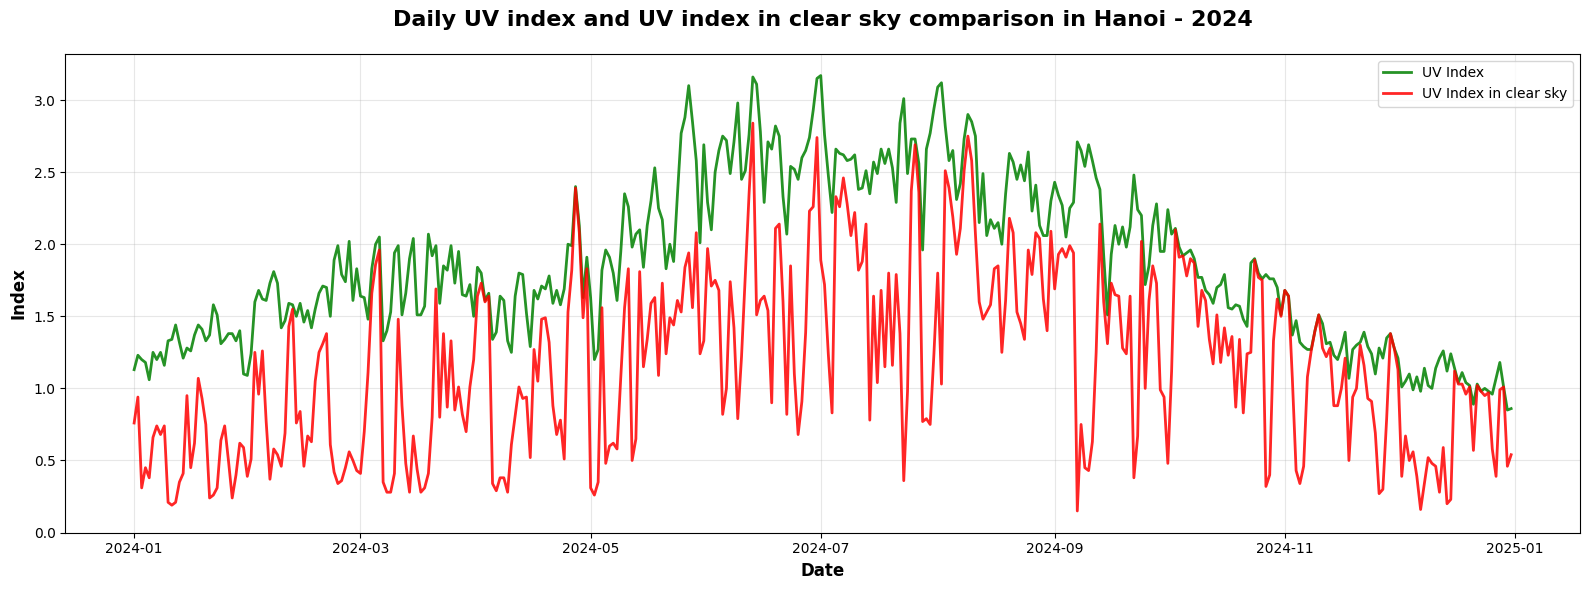

In [162]:
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(pm_df['date'], pm_df['uv_index_clear_sky ()'], 
        color="green", linewidth=2, alpha=0.85, label='UV Index')

ax.plot(pm_df['date'], pm_df['uv_index ()'], 
        color="red", linewidth=2, alpha=0.85, label='UV Index in clear sky')

ax.set_title('Daily UV index and UV index in clear sky comparison in Hanoi - 2024', 
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('Index', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../figures/uv_index_over_time.png", dpi=300, bbox_inches='tight')
plt.show()

# Temperature prediction

## Create time series data for tavg

In [163]:
clean_df

,tavg,tmin,tmax,prcp,wspd,pres,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted
date,,,,,,,,,,,,,,,,,
2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False


Text(0.5, 0, 'Date')

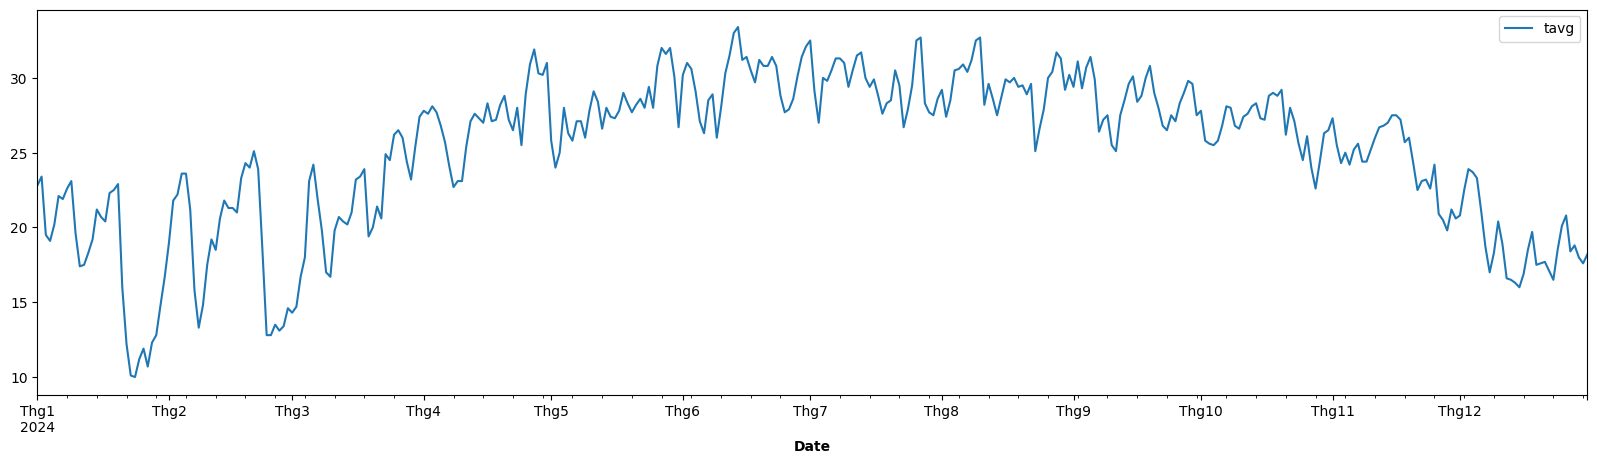

In [193]:
tavg_data = clean_df[clean_df["is_deleted"] == False][["tavg"]].reset_index()
ax = tavg_data.plot.line(x="date", y="tavg", figsize=(20,5))
ax.set_xlabel("Date", fontweight="bold")

In [165]:
def create_ts_data(data, window_size=5):
    ts_data = data.copy()
    
    for i in range(window_size):
        shift_amount = window_size - i
        ts_data[f"tavg_{i + 1}"] = ts_data["tavg"].shift(shift_amount)

    ts_data["target"] = ts_data["tavg"]
    ts_data = ts_data.drop(columns=["tavg"])
    ts_data = ts_data.dropna()
    return ts_data 

In [166]:
tavg_data = create_ts_data(tavg_data)
tavg_data 

,date,tavg_1,tavg_2,tavg_3,tavg_4,tavg_5,target
5,2024-01-06,22.8,23.4,19.5,19.1,20.2,22.1
6,2024-01-07,23.4,19.5,19.1,20.2,22.1,21.9
7,2024-01-08,19.5,19.1,20.2,22.1,21.9,22.6
8,2024-01-09,19.1,20.2,22.1,21.9,22.6,23.1
9,2024-01-10,20.2,22.1,21.9,22.6,23.1,19.6
...,...,...,...,...,...,...,...
361,2024-12-27,17.1,16.5,18.5,20.1,20.8,18.4
362,2024-12-28,16.5,18.5,20.1,20.8,18.4,18.8
363,2024-12-29,18.5,20.1,20.8,18.4,18.8,18.0
364,2024-12-30,20.1,20.8,18.4,18.8,18.0,17.6


## Train test split

In [167]:
X = tavg_data.drop(columns=["date","target"])
y = tavg_data["target"]

In [168]:
train_size = int(len(tavg_data) * 0.8)

X_train = X[:train_size]
y_train = y[:train_size]
X_test = X[train_size:]
y_test = y[train_size:]

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((288, 5), (288,), (73, 5), (73,))

## Model

In [169]:
model = RandomForestRegressor()
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [170]:
y_pred = model.predict(X_test)

In [171]:
print(f"R2: {r2_score(y_test, y_pred)}")

R2: 0.8108273614564625


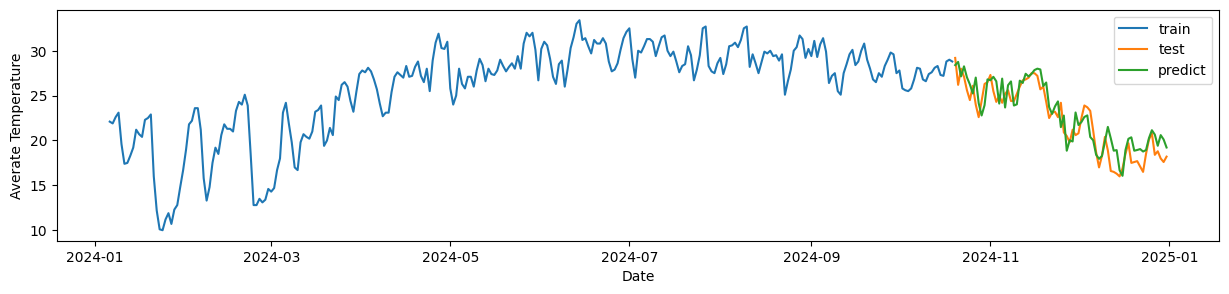

In [172]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15,3))
ax.plot(tavg_data["date"][:train_size], tavg_data["target"][:train_size], label="train")
ax.plot(tavg_data["date"][train_size:], tavg_data["target"][train_size:], label="test")
ax.plot(tavg_data["date"][train_size:], y_pred, label="predict")
ax.set_xlabel("Date")
ax.set_ylabel("Averate Temperature")
plt.legend()
plt.show()

In [173]:
feature_names = X_train.columns.tolist()

days_predict = 14
future_pred = []
future_dates = pd.date_range(start='2025-01-01', periods=days_predict)
curr_window = tavg_data["target"].values[-5:]

for i in range(days_predict):
    input_data = curr_window.reshape(1,-1)
    input_df = pd.DataFrame(input_data, columns=feature_names)

    pred = model.predict(input_df)[0]

    future_pred.append(pred)
    curr_window = np.append(curr_window[1:], pred)



In [174]:
predict_df_2025 = pd.DataFrame({
    'date': future_dates,
    'predicted_tavg': future_pred
})

In [175]:
predict_df_2025

,date,predicted_tavg
0,2025-01-01,19.821
1,2025-01-02,20.572
2,2025-01-03,20.928
3,2025-01-04,21.130
4,2025-01-05,21.710
5,2025-01-06,22.146
6,2025-01-07,22.803
7,2025-01-08,22.632
8,2025-01-09,20.752
9,2025-01-10,18.413


In [176]:
weather_2025_df = pd.read_csv("../raw/weather_2025.csv")
weather_2025_df = weather_2025_df[["date", "tavg"]][:days_predict]
type(weather_2025_df["date"][0])
weather_2025_df["date"] = pd.to_datetime(weather_2025_df["date"], errors="coerce")
type(weather_2025_df["date"][0])

pandas._libs.tslibs.timestamps.Timestamp

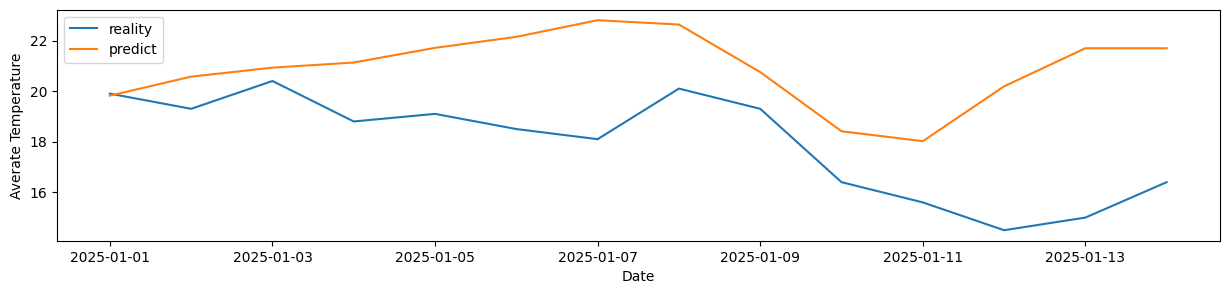

In [177]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15,3))
ax.plot(weather_2025_df["date"], weather_2025_df["tavg"], label="reality")
ax.plot(predict_df_2025["date"], predict_df_2025["predicted_tavg"], label="predict")
ax.set_xlabel("Date")
ax.set_ylabel("Averate Temperature")
plt.legend()
plt.show()